In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/nyc_daily_1981_2025.csv", index_col="date", parse_dates=True)

df["high_f"] = df["T2M_MAX"] * 9 / 5 + 32
df["avg_f"] = df["T2M"] * 9 / 5 + 32

df.head()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,high_f,avg_f
date,,,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31,29.696,27.806
1981-01-02,-1.12,1.64,-5.48,1.09,77.30,34.952,29.984
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84,29.606,24.116
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84,21.020,13.604
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55,27.968,21.092


In [2]:
df["high_f"].max()

np.float64(93.65)

In [3]:
df["high_f"].idxmax()

Timestamp('2010-07-06 00:00:00')

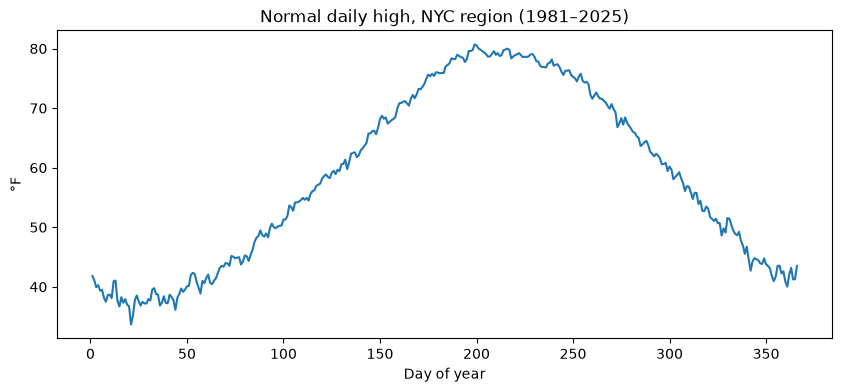

In [4]:
df["doy"] = df.index.day_of_year

normal_high = df.groupby("doy")["high_f"].mean()

normal_high.plot(figsize=(10, 4), title="Normal daily high, NYC region (1981–2025)")
plt.xlabel("Day of year")
plt.ylabel("°F")
plt.show()

In [5]:
normal_high.loc[1]

np.float64(41.8152)

In [6]:
normal_high.loc[200]

np.float64(80.5352)

In [7]:
normal_high.idxmax()

np.int32(199)

In [8]:
df["normal_high"] = df["doy"].map(normal_high)
df["high_anom"] = df["high_f"] - df["normal_high"]

df[["high_f", "normal_high", "high_anom"]].tail()

,high_f,normal_high,high_anom
date,,,
2025-12-27,37.490,40.0356,-2.5456
2025-12-28,40.892,42.0584,-1.1664
2025-12-29,46.004,43.1860,2.8180
2025-12-30,33.440,41.2472,-7.8072
2025-12-31,34.790,41.2756,-6.4856


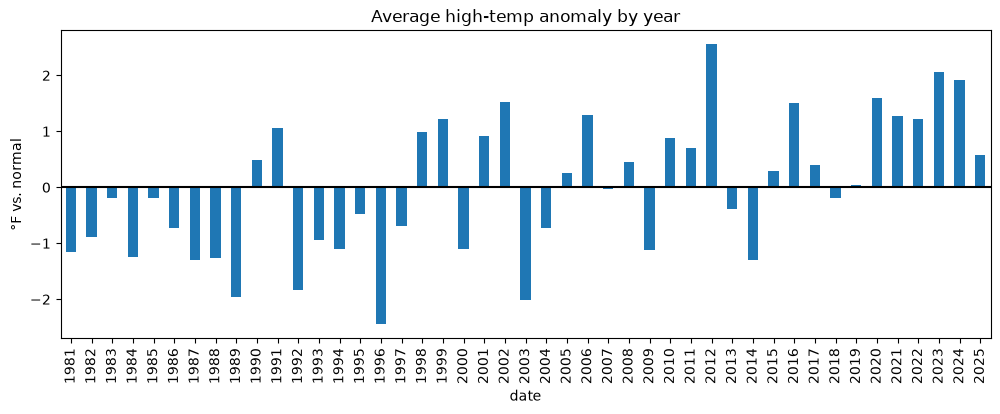

In [9]:
yearly_anom = df["high_anom"].groupby(df.index.year).mean()

yearly_anom.plot(kind="bar", figsize=(12, 4), title="Average high-temp anomaly by year")
plt.axhline(0, color="black")
plt.ylabel("°F vs. normal")
plt.show()

In [10]:
df["high_anom"].idxmax()

Timestamp('2002-04-17 00:00:00')

In [11]:
df["high_anom"].max()

np.float64(22.647999999999996)

In [12]:
threshold = df["high_f"].quantile(0.95)
print(f"Hot-day threshold: {threshold:.1f}°F")

df["hot"] = df["high_f"] >= threshold
df["run_id"] = (df["hot"] != df["hot"].shift()).cumsum()

df.loc["2010-07-01":"2010-07-10", ["high_f", "hot", "run_id"]]

Hot-day threshold: 81.0°F


,high_f,hot,run_id
date,,,
2010-07-01,75.488,False,399
2010-07-02,76.712,False,399
2010-07-03,80.744,False,399
2010-07-04,84.956,True,400
2010-07-05,87.872,True,400
2010-07-06,93.650,True,400
2010-07-07,87.350,True,400
2010-07-08,80.258,False,401
2010-07-09,80.132,False,401


In [13]:
df["day"] = df.index

hot_days = df[df["hot"]]

streaks = hot_days.groupby("run_id").agg(
    start=("day", "min"),
    end=("day", "max"),
    days=("day", "count"),
    peak_f=("high_f", "max"),
)

heat_waves = streaks[streaks["days"] >= 3].reset_index(drop=True)

print(f"Found {len(heat_waves)} heat waves")
heat_waves.sort_values("days", ascending=False).head(10)

Found 103 heat waves


,start,end,days,peak_f
51,2010-07-15,2010-07-27,13,88.736
18,1995-07-23,1995-08-04,13,85.838
11,1988-08-07,1988-08-18,12,86.180
27,1999-07-23,1999-08-03,12,88.790
89,2022-08-02,2022-08-12,11,87.548
44,2006-07-27,2006-08-05,10,89.546
15,1993-07-07,1993-07-16,10,89.492
59,2012-06-29,2012-07-08,10,89.150
72,2016-08-11,2016-08-19,9,86.828
66,2015-07-28,2015-08-05,9,85.010


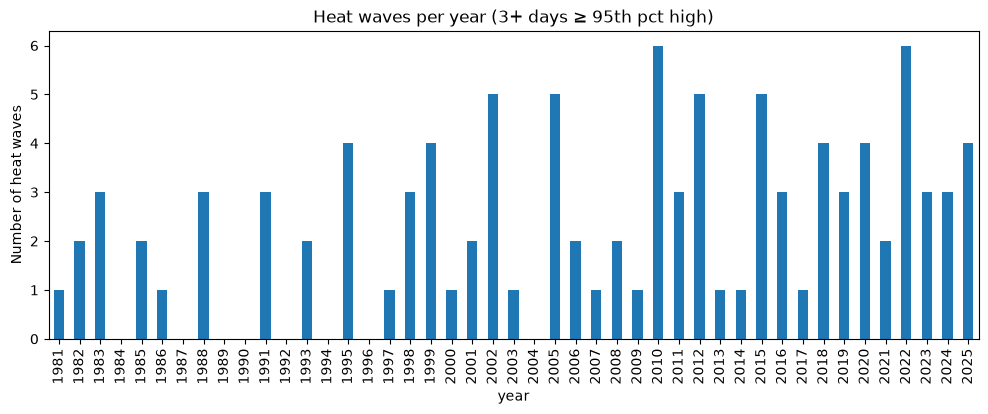

Avg per year, 1981–2000: 1.5
Avg per year, 2006–2025: 3.0


In [14]:
heat_waves["year"] = heat_waves["start"].dt.year

waves_per_year = heat_waves.groupby("year").size()
waves_per_year = waves_per_year.reindex(range(1981, 2026), fill_value=0)

waves_per_year.plot(kind="bar", figsize=(12, 4), title="Heat waves per year (3+ days ≥ 95th pct high)")
plt.ylabel("Number of heat waves")
plt.show()

print("Avg per year, 1981–2000:", waves_per_year.loc[1981:2000].mean())
print("Avg per year, 2006–2025:", waves_per_year.loc[2006:2025].mean())

In [15]:
df["dry"] = df["PRECTOTCORR"] < 1
df["dry_run_id"] = (df["dry"] != df["dry"].shift()).cumsum()

dry_days = df[df["dry"]]

dry_spells = dry_days.groupby("dry_run_id").agg(
    start=("day", "min"),
    end=("day", "max"),
    days=("day", "count"),
)

dry_spells.sort_values("days", ascending=False).head(10)

,start,end,days
dry_run_id,,,
5481,2024-09-30,2024-11-09,41
2505,2001-10-17,2001-11-19,34
5,1981-01-08,1981-01-31,24
4187,2015-04-23,2015-05-15,23
1275,1991-10-18,1991-11-09,23
2277,1999-11-03,1999-11-24,22
2653,2003-01-07,2003-01-28,22
2383,2000-10-19,2000-11-08,21
2449,2001-04-22,2001-05-11,20


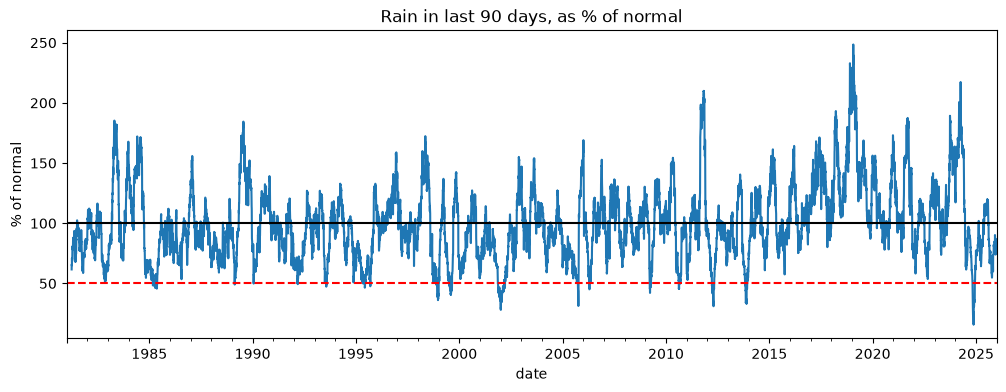

In [16]:
df["rain_90"] = df["PRECTOTCORR"].rolling(90).sum()

normal_rain_90 = df.groupby("doy")["rain_90"].mean()
df["rain_90_normal"] = df["doy"].map(normal_rain_90)

df["rain_90_pct"] = df["rain_90"] / df["rain_90_normal"] * 100

df["rain_90_pct"].plot(figsize=(12, 4), title="Rain in last 90 days, as % of normal")
plt.axhline(100, color="black")
plt.axhline(50, color="red", linestyle="--")
plt.ylabel("% of normal")
plt.show()

In [17]:
df["rain_90_pct"].idxmin()

Timestamp('2024-11-18 00:00:00')

In [18]:
df["rain_90_pct"].min()

np.float64(15.91225177762223)

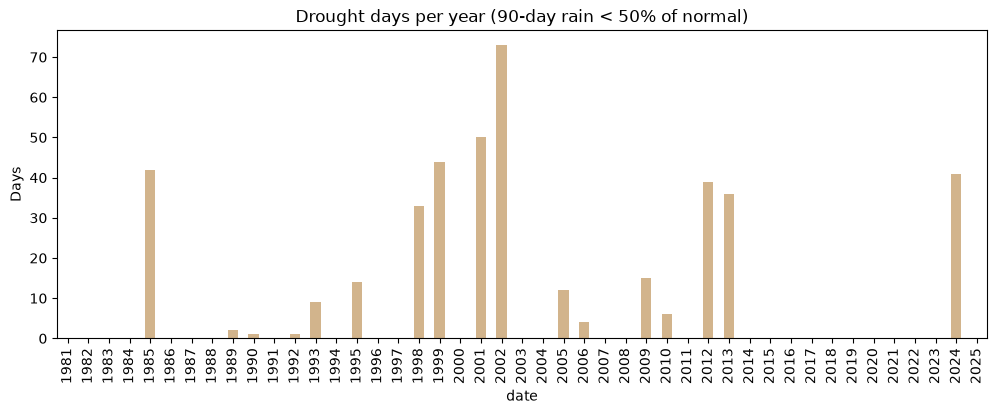

date
2002    73
2001    50
1999    44
1985    42
2024    41
Name: drought, dtype: int64

In [19]:
df["drought"] = df["rain_90_pct"] < 50

drought_days = df["drought"].groupby(df.index.year).sum()

drought_days.plot(kind="bar", figsize=(12, 4), color="tan", title="Drought days per year (90-day rain < 50% of normal)")
plt.ylabel("Days")
plt.show()

drought_days.sort_values(ascending=False).head(5)

Flagged 164 weird days


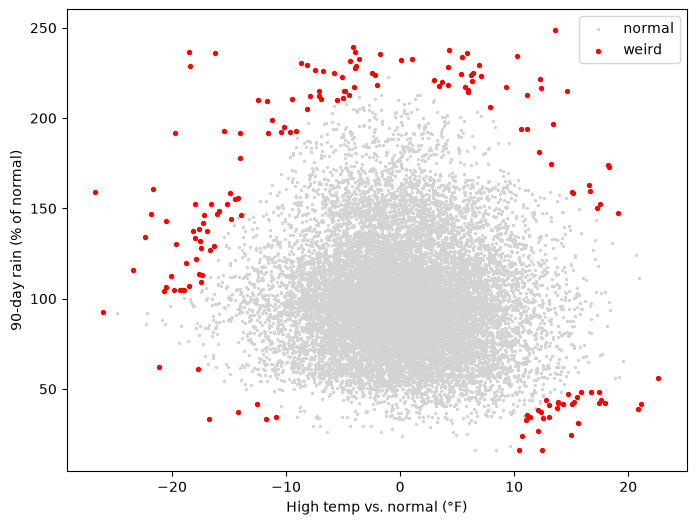

In [20]:
from sklearn.ensemble import IsolationForest

X = df[["high_anom", "rain_90_pct"]].dropna()

model = IsolationForest(contamination=0.01, random_state=42)
labels = model.fit_predict(X)

weird = X[labels == -1]
print(f"Flagged {len(weird)} weird days")

plt.figure(figsize=(8, 6))
plt.scatter(X["high_anom"], X["rain_90_pct"], s=2, color="lightgray", label="normal")
plt.scatter(weird["high_anom"], weird["rain_90_pct"], s=8, color="red", label="weird")
plt.xlabel("High temp vs. normal (°F)")
plt.ylabel("90-day rain (% of normal)")
plt.legend()
plt.show()

In [21]:
weird.index.year.value_counts().head()

date
2019    37
2018    28
2024    17
2002     9
2015     7
Name: count, dtype: int64

In [22]:
weird.loc["2018":"2019"].describe()

,high_anom,rain_90_pct
count,65.000000,65.000000
mean,-2.549446,213.926757
std,9.467726,29.047664
min,-23.424800,104.098025
25%,-8.198000,212.262429
50%,-3.897600,221.130975
75%,5.698000,229.397638
max,14.638400,248.500613


## Sprint 5 findings
- **Heat waves** (3+ days in a row above the 95th-percentile high, ~81°F): 103 in 45 years.
- They **doubled**: 1.5 per year (1981–2000) vs. 3.0 per year (2006–2025). Longest ones were in 2010 and 1995.
- **Longest dry spell**: fall 2024, with 2001 second.
- **Most severe drought**: the 90 days ending 2024-11-18 got only 16% of normal rain.
- **Most drought days**: 2002, 2001, 1999 (the 1999–2002 multi-year drought). No clear trend over time.
- 2024 was *intense but short*; 1999–2002 was *long*. Severity and duration are different measures.
- **IsolationForest** flagged the weirdest 1% of days. Top years were 2019 and 2018, which were extreme *wet* periods (~214% of normal rain), not heat or drought. Unsupervised ML finds "unusual"; a human has to explain it.